# Global suicide mortality rates, 2000–2021

## 1. Dataset selection and preliminary research

### 1a. Dataset

The dataset has 18,315 rows and 10 columns: suicide mortality rates (deaths per 100,000 people) for 185 countries from 2000 to 2021, split by sex (both, male, female) and age bracket. Each row also has GDP, GDP per capita and population for that country and year. Age-bracket rows exist only for 2021, so the time analysis uses the all-ages rows.

**Source:** World Health Organization, Global Health Observatory, suicide mortality rate (per 100 000 population): https://www.who.int/data/gho/data/indicators/indicator-details/GHO/crude-suicide-rates-(per-100-000-population). GDP, GDP per capita and population come from the World Bank, World Development Indicators (NY.GDP.MKTP.CD, NY.GDP.PCAP.CD, SP.POP.TOTL): https://data.worldbank.org/

In [1]:
%pip install kagglehub

In [2]:
%pip install seaborn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

YEAR = 2019
INCOME_LABELS = ["Low", "Lower-middle", "Upper-middle", "High"]

In [4]:
import os
import kagglehub
path = kagglehub.dataset_download("samartalwar/global-suicide-rates-and-socioeconomic-indicators")
raw = pd.read_csv(os.path.join(path, "global_suicide_rates_real_who_worldbank.csv"))
print(raw.shape)
raw.info()
raw.head()

/lib/python3.14/site-packages/kagglehub/clients.py:244: TqdmMonitorWarning: tqdm:disabling monitor support (monitor_interval = 0) due to:
can't start new thread
  with tqdm(total=total_size, initial=size_read, unit="B", unit_scale=True, unit_divisor=1024) as progress_bar:
100%|██████████| 215k/215k [00:00<00:00, 221MB/s]


Extracting files...
(18315, 10)
<class 'pandas.DataFrame'>
RangeIndex: 18315 entries, 0 to 18314
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   18315 non-null  str    
 1   country_code              18315 non-null  str    
 2   year                      18315 non-null  int64  
 3   sex                       18315 non-null  str    
 4   age_bracket               18315 non-null  str    
 5   suicide_rate_per_100k     18315 non-null  float64
 6   generation                18315 non-null  str    
 7   gdp_usd                   18000 non-null  float64
 8   gdp_per_capita_usd        18000 non-null  float64
 9   total_country_population  18315 non-null  float64
dtypes: float64(4), int64(1), str(5)
memory usage: 1.0 MB


,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,generation,gdp_usd,gdp_per_capita_usd,total_country_population
0,Afghanistan,AFG,2000,both,all_ages,4.36,All Cohorts,3.521418e+09,174.930991,20130327.0
1,Afghanistan,AFG,2000,female,all_ages,2.91,All Cohorts,3.521418e+09,174.930991,20130327.0
2,Afghanistan,AFG,2000,male,all_ages,5.79,All Cohorts,3.521418e+09,174.930991,20130327.0
3,Afghanistan,AFG,2001,both,all_ages,4.38,All Cohorts,2.813572e+09,138.706822,20284307.0
4,Afghanistan,AFG,2001,female,all_ages,2.92,All Cohorts,2.813572e+09,138.706822,20284307.0


In [27]:
print("countries:", raw["country"].nunique(), "in years:", raw["year"].min(), "-", raw["year"].max())
print(raw.groupby("age_bracket")["year"].agg(["min", "max", "nunique"]).T.to_string())
raw[["suicide_rate_per_100k", "gdp_per_capita_usd", "total_country_population"]].describe()


countries: 185 in years: 2000 - 2021
age_bracket  10-19  15-19  15-29  20-29  30-39  30-49  40-49  50-59  50-69  60-69  70plus  all_ages
min           2021   2021   2021   2021   2021   2021   2021   2021   2021   2021    2021      2000
max           2021   2021   2021   2021   2021   2021   2021   2021   2021   2021    2021      2021
nunique          1      1      1      1      1      1      1      1      1      1       1        22


,suicide_rate_per_100k,gdp_per_capita_usd,total_country_population
count,"18,315.00","18,000.00","18,315.00"
mean,10.41,"13,079.32","39,481,311.79"
std,11.53,"19,662.07","143,217,757.92"
min,0.00,109.59,"74,912.00"
25%,3.43,"1,459.60","2,567,168.00"
50%,6.84,"4,536.73","8,953,969.00"
75%,13.08,"15,509.81","28,193,009.00"
max,160.59,"134,965.82","1,414,203,896.00"


### 1b. Preliminary research

The rate is the number of suicide deaths per 100,000 people in a year. Reporting quality differs between countries, and very small countries give unstable rates.

Questions to explore:
1. Have rates changed since 2000?
2. Is the male rate higher than the female rate?
3. Is a country's income related to its suicide rate?

## 2. Data cleaning and preprocessing

### 2a. Cleaning

In [28]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [29]:
df = raw.copy()
print("duplicate rows:", df.duplicated().sum(),
      "| duplicate keys:", df.duplicated(["country", "year", "sex", "age_bracket"]).sum())
df = df.drop(columns="generation")
df.dtypes.to_frame("dtype")

duplicate rows: 0 | duplicate keys: 0


,dtype
country,str
country_code,str
year,int64
sex,str
age_bracket,str
suicide_rate_per_100k,float64
gdp_usd,float64
gdp_per_capita_usd,float64
total_country_population,float64


### missing values

In [30]:
print(df.isna().sum()[lambda s: s > 0].to_string())

gdp_usd               315
gdp_per_capita_usd    315


In [31]:
miss = df[df["gdp_usd"].isna()].groupby("country").agg(rows=("year", "size"))
miss

,rows
country,
Cuba,36
Eritrea,63
"Korea, Democratic People's Republic of",99
South Sudan,75
Yemen,42


missing values were found only in the two GDP columns, for 5 countries, and the rows were kept.

In [32]:
zero = df[df["suicide_rate_per_100k"] == 0]
zero

,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,gdp_usd,gdp_per_capita_usd,total_country_population
397,Antigua and Barbuda,ATG,2000,female,all_ages,0.00,"901,003,703.70","12,027.49","74,912.00"
400,Antigua and Barbuda,ATG,2001,female,all_ages,0.00,"877,774,074.07","11,539.18","76,069.00"
403,Antigua and Barbuda,ATG,2002,female,all_ages,0.00,"898,092,592.59","11,658.69","77,032.00"
406,Antigua and Barbuda,ATG,2003,female,all_ages,0.00,"948,100,000.00","12,173.23","77,884.00"
409,Antigua and Barbuda,ATG,2004,female,all_ages,0.00,"1,026,329,629.63","13,037.89","78,719.00"
...,...,...,...,...,...,...,...,...,...
13951,Saint Vincent and the Grenadines,VCT,2021,male,30-39,0.00,"888,677,777.78","8,641.28","102,841.00"
13952,Saint Vincent and the Grenadines,VCT,2021,male,30-49,0.00,"888,677,777.78","8,641.28","102,841.00"
13953,Saint Vincent and the Grenadines,VCT,2021,male,40-49,0.00,"888,677,777.78","8,641.28","102,841.00"
13956,Saint Vincent and the Grenadines,VCT,2021,male,60-69,0.00,"888,677,777.78","8,641.28","102,841.00"


In [33]:
pop = df.groupby("country")["total_country_population"].mean()
pop

country
Afghanistan                         32,978,034.61
Albania                              2,728,346.88
Algeria                             39,633,667.24
Angola                              27,757,517.39
Antigua and Barbuda                     87,319.12
                                         ...     
Venezuela, Bolivarian Republic of   28,211,963.61
Viet Nam                            91,537,031.79
Yemen                               30,776,107.58
Zambia                              16,133,150.85
Zimbabwe                            14,326,598.33
Name: total_country_population, Length: 185, dtype: float64

In [34]:
print("zero-rate rows:", len(zero), "| countries:", zero["country"].nunique())
print(pop[zero["country"].unique()].sort_values().round(0).to_string())

zero-rate rows: 153 | countries: 10
country
Antigua and Barbuda                   87,319.00
Saint Vincent and the Grenadines     107,070.00
Grenada                              113,702.00
Iceland                              337,935.00
Brunei Darussalam                    412,513.00
Malta                                460,991.00
Luxembourg                           563,059.00
Cyprus                             1,196,304.00
Armenia                            3,032,230.00
Panama                             3,896,000.00


In [35]:
allages = df[df["age_bracket"] == "all_ages"]
allages

,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,gdp_usd,gdp_per_capita_usd,total_country_population
0,Afghanistan,AFG,2000,both,all_ages,4.36,"3,521,418,059.92",174.93,"20,130,327.00"
1,Afghanistan,AFG,2000,female,all_ages,2.91,"3,521,418,059.92",174.93,"20,130,327.00"
2,Afghanistan,AFG,2000,male,all_ages,5.79,"3,521,418,059.92",174.93,"20,130,327.00"
3,Afghanistan,AFG,2001,both,all_ages,4.38,"2,813,571,753.87",138.71,"20,284,307.00"
4,Afghanistan,AFG,2001,female,all_ages,2.92,"2,813,571,753.87",138.71,"20,284,307.00"
...,...,...,...,...,...,...,...,...,...
18277,Zimbabwe,ZWE,2020,female,all_ages,10.35,"31,979,753,644.66","2,059.64","15,526,888.00"
18278,Zimbabwe,ZWE,2020,male,all_ages,21.21,"31,979,753,644.66","2,059.64","15,526,888.00"
18290,Zimbabwe,ZWE,2021,both,all_ages,17.34,"41,287,852,523.50","2,613.62","15,797,210.00"
18302,Zimbabwe,ZWE,2021,female,all_ages,11.71,"41,287,852,523.50","2,613.62","15,797,210.00"


In [36]:
r = allages[(allages["sex"] == "both") & (allages["year"] == YEAR)].set_index("country")["suicide_rate_per_100k"]
q1, q3 = r.quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
r

country
Afghanistan                          3.53
Albania                              3.78
Algeria                              2.05
Angola                               7.52
Antigua and Barbuda                  0.00
                                     ... 
Venezuela, Bolivarian Republic of    7.17
Viet Nam                             7.53
Yemen                                4.33
Zambia                               5.76
Zimbabwe                            15.84
Name: suicide_rate_per_100k, Length: 185, dtype: float64

In [37]:
print(f"{YEAR}: median = {r.median():.2f} - IQR upper fence = {fence:.1f} - countries above fence: {(r > fence).sum()} of {len(r)}")
r[r > fence].sort_values(ascending=False).round(1).to_frame("rate")

2019: median = 7.38 - IQR upper fence = 24.6 - countries above fence: 6 of 185


,rate
country,
Lesotho,28.80
"Korea, Republic of",28.40
Eswatini,28.10
Guyana,27.60
Lithuania,26.30
Suriname,26.30


- Data types were already correct, so nothing was changed. There are no duplicate rows. `generation` has one value (All Cohorts) and was dropped.
- GDP is missing in 315 rows, for 5 countries
- The rows were kept, and those countries are left out only of the GDP analyses.
- 153 rows have a rate of 0. They all belong to , where zero cases in a year is plausible, so they were kept.
- Outliers: with the IQR rule, 6 countries are above the 2019 upper fence of 24.6 (Lesotho, South Korea, Eswatini, Guyana, Lithuania, Suriname). They are real high-rate countries, so they were kept.

### 2b. Transformations

In [38]:
wide = allages.pivot_table(index=["country", "year"], columns="sex", values="suicide_rate_per_100k").reset_index()
meta = (allages[allages["sex"] == "both"]
        [["country", "year", "gdp_per_capita_usd", "total_country_population"]]
        .rename(columns={"gdp_per_capita_usd": "gdp_pc", "total_country_population": "pop"}))
cy = meta.merge(wide, on=["country", "year"])
print(cy.shape)
cy.head()

(4070, 7)


,country,year,gdp_pc,pop,both,female,male
0,Afghanistan,2000,174.93,"20,130,327.00",4.36,2.91,5.79
1,Afghanistan,2001,138.71,"20,284,307.00",4.38,2.92,5.83
2,Afghanistan,2002,178.95,"21,378,117.00",4.26,2.71,5.78
3,Afghanistan,2003,198.87,"22,733,049.00",4.24,2.72,5.74
4,Afghanistan,2004,221.76,"23,560,654.00",4.23,2.81,5.64


the data was reshaped to one row per country and year, with male, female and both-sex rates in separate columns, merged with GDP per capita and population.

In [39]:
#CS = crross-section - this is the table I am going to work on it
cs = cy[cy["year"] == YEAR].dropna(subset=["gdp_pc"])
cs["income"] = pd.qcut(cs["gdp_pc"], 4, labels=INCOME_LABELS) 

#INCOME_LABELS = ["Low", "Lower-middle", "Upper-middle", "High"] - came from world bank

cs["log_gdp"] = np.log10(cs["gdp_pc"]) # for GDP scatter plot
cs["log_rate"] = np.log1p(cs["both"]) #for the Welch test and the histogram
cs["high"] = (cs["both"] > cs["both"].median()).astype(int) #for the chi-square test

print(f"{YEAR}: Sample size : n = {len(cs)}")
print(cs["income"].value_counts())
cs.head()

2019: Sample size : n = 181
income
Low             46
Lower-middle    45
Upper-middle    45
High            45
Name: count, dtype: int64


,country,year,gdp_pc,pop,both,female,male,income,log_gdp,log_rate,high
19,Afghanistan,2019,496.60,"37,856,121.00",3.53,2.37,4.66,Low,2.70,1.51,0
41,Albania,2019,"6,069.44","2,567,801.00",3.78,2.70,4.89,Upper-middle,3.78,1.56,0
63,Algeria,2019,"4,468.45","43,294,546.00",2.05,1.41,2.66,Lower-middle,3.65,1.12,0
85,Angola,2019,"2,507.87","32,375,632.00",7.52,3.40,11.73,Lower-middle,3.40,2.14,1
107,Antigua and Barbuda,2019,"18,896.37","91,364.00",0.00,0.00,0.00,High,4.28,0.00,0


- The sex rows were pivoted into male, female and both columns and merged with GDP and population.
- One row per country was kept for 2019 (181 countries with GDP), so each country counts once in the tests.
- Countries were grouped into four income groups using GDP per capita (approximate World Bank cut-offs: 1,035 / 4,045 / 12,535 US dollars).
- Log GDP, log population and log(1 + rate) were created because the rates are skewed and include zeros.
- `high` marks countries above the 2019 median rate (7.38).

## 3. Exploratory data analysis

### 3a-i. Distributions (histograms)

In [40]:
cs

,country,year,gdp_pc,pop,both,female,male,income,log_gdp,log_rate,high
19,Afghanistan,2019,496.60,"37,856,121.00",3.53,2.37,4.66,Low,2.70,1.51,0
41,Albania,2019,"6,069.44","2,567,801.00",3.78,2.70,4.89,Upper-middle,3.78,1.56,0
63,Algeria,2019,"4,468.45","43,294,546.00",2.05,1.41,2.66,Lower-middle,3.65,1.12,0
85,Angola,2019,"2,507.87","32,375,632.00",7.52,3.40,11.73,Lower-middle,3.40,2.14,1
107,Antigua and Barbuda,2019,"18,896.37","91,364.00",0.00,0.00,0.00,High,4.28,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...
3957,Vanuatu,2019,"3,635.62","291,985.00",16.15,6.96,25.10,Lower-middle,3.56,2.84,1
3979,"Venezuela, Bolivarian Republic of",2019,"2,523.12","28,938,098.00",7.17,1.78,12.67,Lower-middle,3.40,2.10,0
4001,Viet Nam,2019,"3,440.90","97,173,776.00",7.53,4.47,10.73,Lower-middle,3.54,2.14,1
4045,Zambia,2019,"1,258.99","18,513,839.00",5.76,2.12,9.48,Low,3.10,1.91,0


In [42]:
cs[["both", "male", "female", "gdp_pc", "pop"]].describe()

,both,male,female,gdp_pc,pop
count,181.00,181.00,181.00,181.00,181.00
mean,8.90,13.76,4.16,"14,381.65","42,356,511.44"
std,6.27,10.19,3.05,"19,717.93","151,718,458.90"
min,0.00,0.00,0.00,234.31,"91,364.00"
25%,4.55,6.56,2.00,"2,141.77","2,638,657.00"
50%,7.38,11.36,3.47,"6,030.69","9,529,966.00"
75%,12.57,18.09,6.25,"18,315.74","30,063,799.00"
max,28.77,48.00,16.67,"112,696.65","1,407,745,000.00"


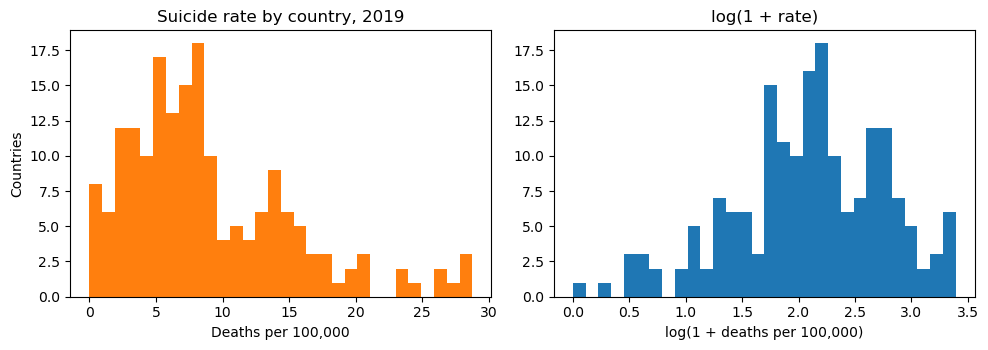

In [43]:
plt.figure(figsize=(10, 3.6))
plt.subplot(1, 2, 1)
plt.hist(cs["both"], bins=30)
plt.hist(cs["both"], bins=30)
plt.title("Suicide rate by country, 2019")
plt.xlabel("Deaths per 100,000")
plt.ylabel("Countries")
#So the big values get pulled in toward the rest, and the small values are spread out a bit.
plt.subplot(1, 2, 2)
plt.hist(cs["log_rate"], bins=30)
plt.title("log(1 + rate)")
plt.xlabel("log(1 + deaths per 100,000)")
#ylabel same Y axis
plt.tight_layout()
plt.show()

In [44]:
print(cs["both"].skew(), cs["log_rate"].skew())
#0.5 and +0.5 is roughly symmetric, and above +1 is strongly right-skewed

1.1569593792985684 -0.45729721396816986


The 2019 rates range from 0 to 28.8 with a median of 7.4. The distribution is skewed to the right (skewness 1.15). After log(1 + rate) it is much closer to symmetric (-0.45), so the log scale is used in the tests.

### 3a-ii. Relationships (scatter plots and correlation matrix)

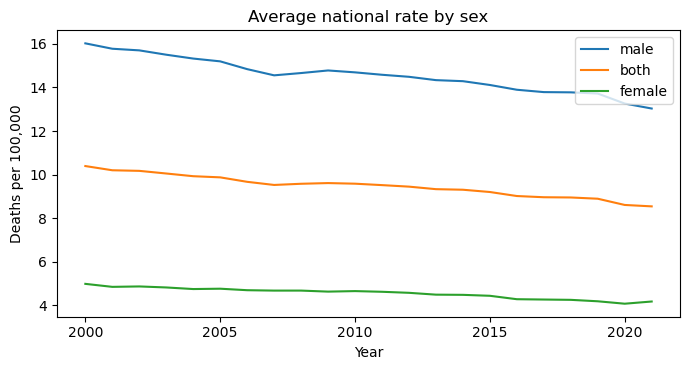

,male,both,female
year,,,
2000,16.02,10.40,4.99
2010,14.69,9.59,4.66
2019,13.72,8.90,4.19
2021,13.03,8.55,4.18


In [48]:
#tr = trend
tr= cy.groupby("year")[["male", "both", "female"]].mean()
plt.figure(figsize=(7, 3.8))
plt.plot(tr.index, tr["male"], label="male")
plt.plot(tr.index, tr["both"], label="both")
plt.plot(tr.index, tr["female"], label="female")

plt.title("Average national rate by sex")
plt.xlabel("Year")
plt.ylabel("Deaths per 100,000")
plt.legend()
plt.tight_layout()
plt.show()
tr.loc[[2000, 2010, 2019, 2021]]

The average national rate fell from 10.4 per 100,000 in 2000 to 8.5 in 2021 (about −18%). The male rate fell from 16.0 to 13.0 and the female rate from 5.0 to 4.2. The male line stays about three times above the female line. This is an average across countries, with each country counted once, so it is not a global rate

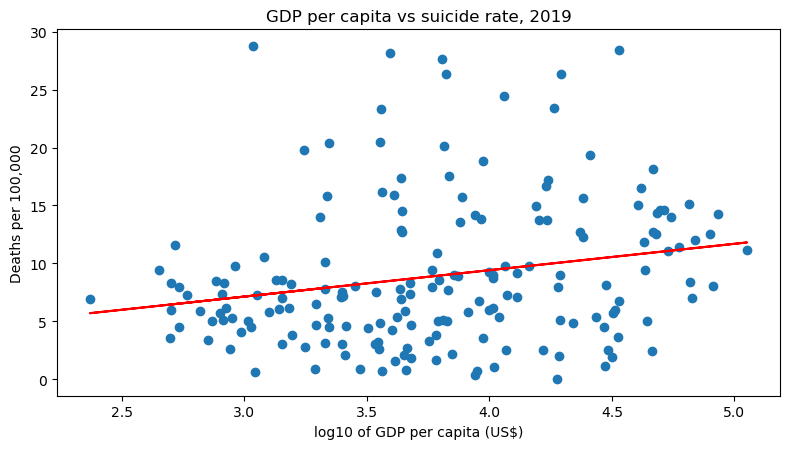

0.24773172390129003 0.0007727756193340176 181


In [49]:
from sklearn.linear_model import LinearRegression

X = cs[["log_gdp"]]
y = cs["both"]
model = LinearRegression().fit(X, y)

plt.figure(figsize=(8, 4.6))
plt.scatter(X, y)
plt.plot(X, model.predict(X), color="red")
plt.title(f"GDP per capita vs suicide rate, {YEAR}")
plt.xlabel("log10 of GDP per capita (US$)")
plt.ylabel("Deaths per 100,000")
plt.tight_layout()
plt.show()

rho, p = stats.spearmanr(cs["log_gdp"], cs["both"]) # p-calue
print(rho, p, len(cs))

p = 0.0008 is below 0.05, so the relationship is unlikely to be chance.

Richer countries tend to have slightly higher suicide rates (Spearman ρ = 0.25, p < 0.001, n = 181). The relationship is weak and the points are widely scattered. This is an association between countries in one year and does not show that income causes the difference

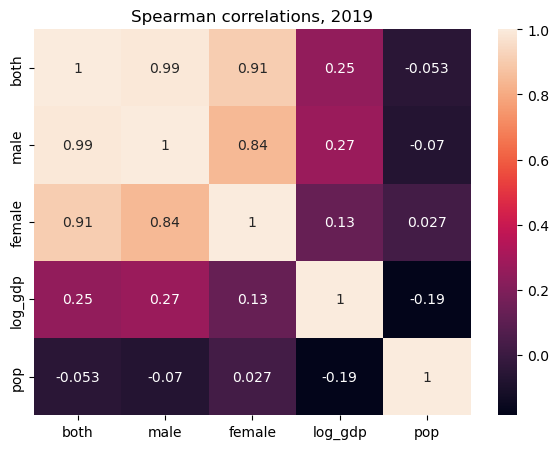

In [50]:
corr_matrix = cs[["both", "male", "female", "log_gdp", "pop"]].corr(method="spearman")

plt.figure(figsize=(6, 4.6))
sns.heatmap(corr_matrix, annot=True)
plt.title(f"Spearman correlations, {YEAR}")
plt.tight_layout()
plt.show()




Male and female rates are strongly related across countries (Spearman 0.84). GDP per capita is weakly related to the rate(0.25), more so for men (0.27) than for women (0.13). Population is unrelated to the rate (about 0)

### 3a-iii. Group comparisons (box plots and bar charts)

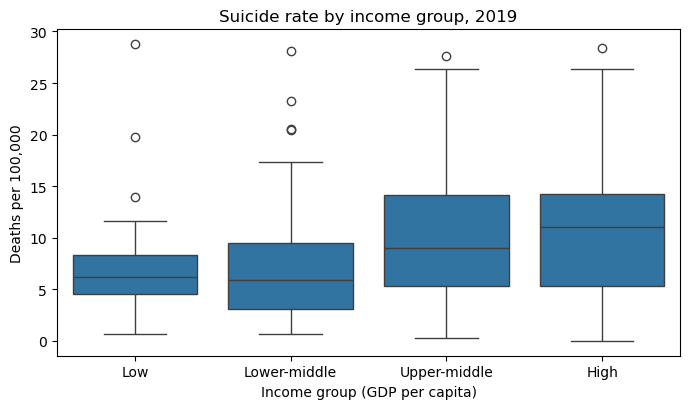

,count,median,mean,std
income,,,,
Low,46,6.16,7.09,4.69
Lower-middle,45,5.88,7.91,6.59
Upper-middle,45,8.99,10.41,6.94
High,45,11.05,10.24,6.18


In [51]:
plt.figure(figsize=(7, 4.2))
sns.boxplot(data=cs, x="income", y="both")
plt.title(f"Suicide rate by income group, {YEAR}")
plt.xlabel("Income group (GDP per capita)")
plt.ylabel("Deaths per 100,000")
plt.tight_layout()
plt.show()

cs.groupby("income")["both"].agg(["count", "median", "mean", "std"])

The median rate is about 6 per 100,000 in the two lower-income groups, 9.0 in the upper-middle group and 11.1 in the highest group. The groups overlap a lot, so income does not separate countries clearly

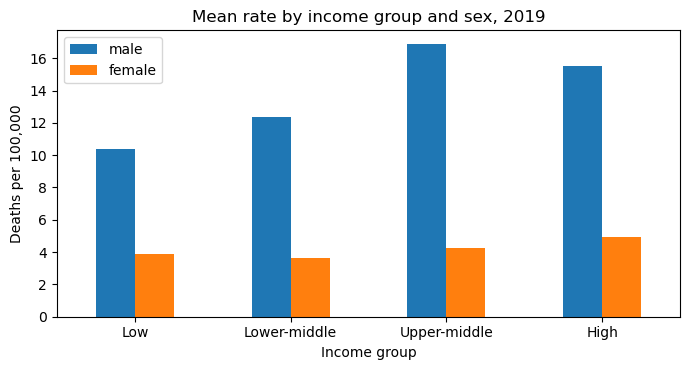

,male,female
income,,
Low,10.38,3.86
Lower-middle,12.35,3.62
Upper-middle,16.88,4.23
High,15.51,4.95


In [52]:
sex_means = cs.groupby("income")[["male", "female"]].mean()

sex_means.plot(kind="bar", figsize=(7, 3.8))
plt.title(f"Mean rate by income group and sex, {YEAR}")
plt.xlabel("Income group")
plt.ylabel("Deaths per 100,000")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

sex_means

The male rate is higher than the female rate in every income group, about three times higher on average. The male mean is 10.4 in the lowest group and 15.5 in the highest, while the female mean only goes from 3.9 to 4.9. The difference between income groups is mostly a difference in male rates.

## 4. Statistical inference

### 4a. Hypotheses

The box plot shows the median rate is higher in the top income group, so two hypotheses are tested (significance level 0.05).

H1. H0: income group and being above the median rate are independent. H1: they are associated.

H2. H0: the mean of log(1 + rate) is the same in the top income group and all other countries. H1: the means differ.

### 4b. Statistical tests

Both tests use the 2019 data with one row per country, so the observations are independent. The chi-square test compares two categorical variables (income group and above or below the median). The Welch t-test compares two group means without assuming equal variances, and it is run on log(1 + rate) because the rates are skewed. The top income group fails the Shapiro-Wilk normality test (p = 0.006), so a Mann-Whitney test is run as a check.

#### Hypothesis 1: chi-square test of independence

In [53]:
ct = pd.crosstab(cs["income"], cs["high"])
ct.columns = ["below median", "above median"]
print(ct)

print(pd.crosstab(cs["income"], cs["high"], normalize="index").round(2))

chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f"chi2({dof}) = {chi2:.2f}, p = {p:.4f}, smallest expected count = {expected.min():.1f}")

              below median  above median
income                                  
Low                     30            16
Lower-middle            27            18
Upper-middle            18            27
High                    16            29
high            0    1
income                
Low          0.65 0.35
Lower-middle 0.60 0.40
Upper-middle 0.40 0.60
High         0.36 0.64
chi2(3) = 11.61, p = 0.0088, smallest expected count = 22.4


chi-square test of independence showed that income group and being above the median rate are associated (p = 0.009). The share of countries above the median rate rises from 35% in the lowest income group to 64% in the highest. We reject H0. This is an association between countries in one year and does not show that income causes the difference

#### Hypothesis 2: Welch t-test

In [54]:
hi = cs.loc[cs["income"] == "High", "log_rate"]
rest = cs.loc[cs["income"] != "High", "log_rate"]
print(len(hi), len(rest), hi.mean(), rest.mean())

print(stats.shapiro(hi).pvalue, stats.shapiro(rest).pvalue)

t = stats.ttest_ind(hi, rest, equal_var=False)
print(t.statistic, t.pvalue)
print(np.exp(hi.mean() - rest.mean()))

u = stats.mannwhitneyu(hi, rest, alternative="two-sided")
print(u.statistic, u.pvalue)

45 136 2.232829666425427 2.0375620645391717
0.006064571933070875 0.09286794461213288
1.6587440902389583 0.10142903186341928
1.2156362495206616
3682.5 0.04118976904285448


A Welch t-test on log(1 + rate) found no significant difference between the top income group and the other countries (t = 1.66, p = 0.10). The top group has a rate about 22% higher. The Shapiro-Wilk test shows the top group is not normal (p = 0.006), so a Mann-Whitney test was run as a check. It gives p = 0.041, borderline significant. The evidence for a difference is weak and depends on the test used.

### 4c. Interpretation of the results

H1: chi-square(3) = 11.61, p = 0.009. The share of countries above the median rate goes from 35% in the lowest income group to 64% in the highest. We reject H0: income group and rate level are associated.

H2: Welch t = 1.66, p = 0.10. The mean log rate is 0.195 higher in the top income group, which is about 1.22 times the rate of the other countries. We do not reject H0 at the 5% level. The top group fails the Shapiro-Wilk normality test (p = 0.006), so a Mann-Whitney check was run. It gives p = 0.041, which is borderline significant, so the evidence for a difference is weak and depends on the test used.

This is an association between countries in one year. It does not show that income causes the difference.

## 5. Visualization and presentation of findings

### 5a. Visualizations of the EDA and test findings

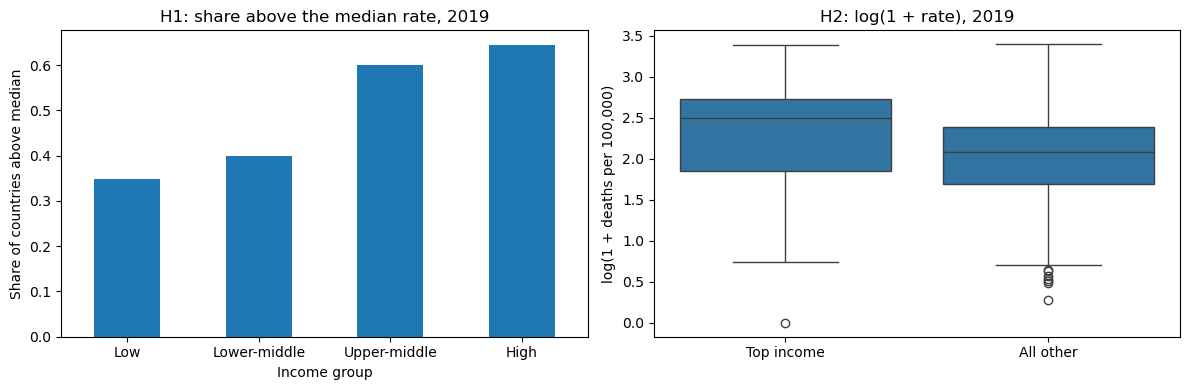

In [55]:
cs["group"] = np.where(cs["income"] == "High", "Top income", "All other")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
cs.groupby("income")["high"].mean().plot(kind="bar")
plt.title(f"H1: share above the median rate, {YEAR}")
plt.xlabel("Income group")
plt.ylabel("Share of countries above median")
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
sns.boxplot(data=cs, x="group", y="log_rate", order=["Top income", "All other"])
plt.title(f"H2: log(1 + rate), {YEAR}")
plt.xlabel("")
plt.ylabel("log(1 + deaths per 100,000)")

plt.tight_layout()
plt.show()

Left: the share of countries above the median rate increases with income (35%, 40%, 60%, 64%), which is the pattern tested in H1. 
Right: the top income group has a slightly higher median log rate than the other countries, but the boxes overlap heavily, which is consistent with the weak result in H2.

### 5b. Visualization libraries

Matplotlib and Seaborn were used for the plots, Pandas and NumPy for data handling, scikit-learn for the regression line, and SciPy for the statistical tests.

## 6. Conclusions

National suicide rates have fallen since 2000 (from 10.4 to 8.5 per 100,000 on average).
The male rate is about three times the female rate in every income group.
Higher-income countries tend to have higher rates. Income group is associated with being above the median rate (chi-square p = 0.009). The difference between the top income group and the other countries is not significant with the Welch test (p = 0.10) and borderline with Mann-Whitney (p = 0.041), so the effect is small and the groups overlap heavily.
These results compare countries in one year. They do not show that income causes the differences.

## 7. Reflection

### 7a. Challenges and how they were overcome

Repeated country rows: each country appears in many years, so rows are not independent. I used one year (2019) and one row per country for the tests.
Age data only for 2021: I used the all-ages rows for the time analysis.
Missing GDP and zero rates: 4 countries have no GDP in 2019, so they were left out of the 2019 analysis (181 remain). The zero rates come from very small countries, so I kept them and used log(1 + rate).
Skewed rates: I used the log scale and a rank-based backup test.
Income groups: the dataset has no income class, so I split the countries into quartiles of GDP per capita. The result of H2 depends on this choice, so it should be read with care.
Cut-off for high: the median is an arbitrary line, so the chi-square result describes this choice.

### 7b. Further questions and advanced analyses

Model all years together (for example a mixed-effects model with country as a random effect) so income and time are tested together.
Add region as a variable and check whether it explains more than income.
Use the 2021 age and sex data to see whether the gap between men and women changes with age.
Test whether 2020 and 2021 break from the earlier downward trend.
Repeat the income comparison with the official World Bank classes and check whether the H2 result changes.
2020 and 2021 were the years during the pandemic, so the data might not be consistent; that is why I chose 2019.